# 06 - Exporting to other tools

`export_of` writes representations in the formats other tools read: OBJ (Blender, most 3D
software), VTK (ParaView), GeoJSON (any GIS, a web map), and a long CSV (pandas, a
spreadsheet). It returns the bytes: write them to a file, or send them in a response.
It runs on **Lutetia**, a synthetic model (CC BY 4.0) built on boreholes of the BRGM Banque du sous-sol (Licence Ouverte 2.0), modified for the example: [geosiris-technologies/energyml-lutetia](https://github.com/geosiris-technologies/energyml-lutetia). The first run downloads it (27 MB) at the commit this repository pins; see `_lutetia.py`.

```
pip install energyml-rust matplotlib pandas
```

In [1]:
import io
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from energyml.rust.epc import Epc
from energyml.rust.resqml import export_of, formats, standard_metadata

from _lutetia import lutetia

root = lutetia()
pkg = Epc.open(str(root / "package" / "Lutetia.epc"))
out = Path(tempfile.mkdtemp())
pd.DataFrame(formats())

,name,extension,mime,describes
0,obj,obj,model/obj,"Wavefront OBJ: triangles and polylines, placed..."
1,csv,csv,text/csv,long-format CSV: one row per element and attri...
2,geojson,geojson,application/geo+json,RFC 7946 GeoJSON in WGS 84 - needs a reproject...
3,vtk,vtk,application/octet-stream,"VTK legacy ASCII, DATASET POLYDATA"
4,vtp,vtp,application/xml,"VTK XML PolyData (.vtp), surfaces and lines"
5,vtu,vtu,application/xml,"VTK XML UnstructuredGrid (.vtu), the general c..."


## A surface for Blender or ParaView

One call, one document: placed in the projected CRS and in metres.

In [2]:
h3 = pkg.find("TriangulatedSetRepresentation", "H3")[0]
obj = export_of(pkg, [h3.uri], "obj")
(out / "h3.obj").write_bytes(obj)
print(obj.decode()[:400])

# H3 - top of the Ypresian (triangulated)
# uuid 0c53403a-0a37-5132-8609-88e4bb21265d
# uri eml:///resqml22.TriangulatedSetRepresentation(0c53403a-0a37-5132-8609-88e4bb21265d)
# type resqml22.TriangulatedSetRepresentation
# interpretation 6856d043-9b12-55c9-904e-0c3a4dcacdca Lutetian (stage) - base
# feature 1a8b9078-dae1-55ea-a694-ed1de815df99 Lutetian (stage) - base
# crs ea058eb0-36cb-5da4-826a


In [3]:
grid = next(g for g in pkg.find("IjkGridRepresentation") if g.title == "Ypresian-Chalk grid")
vtu = export_of(pkg, [grid.uri], "vtu", with_properties=True)
(out / "grid.vtu").write_bytes(vtu)
print(f"{len(vtu) / 1e6:.1f} MB, with the grid's properties as cell arrays")

12.5 MB, with the grid's properties as cell arrays


`with_properties` is off by default, and that is a cost, not a preference: nothing in a
representation lists its properties, so finding them reads every property of the package.

## The same metadata in every format

A metadata spec maps names to dotted paths in the objects - the interpretation, the
feature, the originator - and every format writes the same keys: an OBJ comment, a GeoJSON
property, a VTK field array. `standard_metadata()` is the one the library ships.

In [4]:
json.loads(standard_metadata())

{'contentType': 'contentType',
 'feature': 'RepresentedInterpretation.InterpretedFeature.uuid',
 'featureTitle': 'RepresentedInterpretation.InterpretedFeature.Title',
 'interpretation': 'RepresentedInterpretation.uuid',
 'interpretationTitle': 'RepresentedInterpretation.Title',
 'originator': 'Citation.Originator',
 'qualifiedType': 'qualifiedType',
 'title': 'Citation.Title',
 'uuid': 'uuid'}

## A web map

GeoJSON is WGS 84 by its standard (RFC 7946), so the wells are reprojected from Lambert-93 on
the way out.

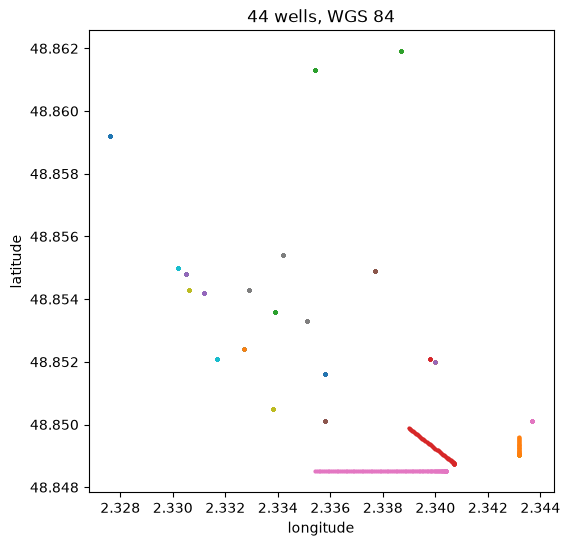

,title,interpretation_title,feature_title
0,BSS000NVHN - trajectory,BSS000NVHN - interpretation,BSS000NVHN
1,BSS000NZNP - trajectory,BSS000NZNP - interpretation,BSS000NZNP
2,BSS000NZWP - trajectory,BSS000NZWP - interpretation,BSS000NZWP
3,BSS000NTGZ - trajectory,BSS000NTGZ - interpretation,BSS000NTGZ
4,BSS000NTCE - trajectory,BSS000NTCE - interpretation,BSS000NTCE


In [5]:
wells = [w.uri for w in pkg.find("WellboreTrajectoryRepresentation")]
collection = json.loads(export_of(pkg, wells, "geojson", metadata=standard_metadata()))
(out / "wells.geojson").write_text(json.dumps(collection))

fig, ax = plt.subplots(figsize=(6, 6))
for feature in collection["features"]:
    for line in feature["geometry"]["coordinates"]:
        lon, lat = zip(*[(point[0], point[1]) for point in line])
        ax.plot(lon, lat, "-o", ms=2)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"{len(collection['features'])} wells, WGS 84")
plt.show()
pd.DataFrame(f["properties"] for f in collection["features"])[["title", "interpretation_title", "feature_title"]].head()

## A table for pandas

The CSV is long: one row per element and attribute, which pandas pivots as it likes.

In [6]:
frame = pd.read_csv(io.BytesIO(export_of(pkg, wells[:3], "csv")))
frame.head()

,object,uuid,element,index,x,y,z,property,kind,uom,value
0,BSS000NVHN - trajectory,02ef8bf7-94e9-5305-8dfa-4e38fd259ff9,node,0,651050.797949,6.861791e+06,32.50,NaN,NaN,NaN,NaN
1,BSS000NVHN - trajectory,02ef8bf7-94e9-5305-8dfa-4e38fd259ff9,node,1,651050.797949,6.861791e+06,32.20,NaN,NaN,NaN,NaN
2,BSS000NVHN - trajectory,02ef8bf7-94e9-5305-8dfa-4e38fd259ff9,node,2,651050.797949,6.861791e+06,29.01,NaN,NaN,NaN,NaN
3,BSS000NVHN - trajectory,02ef8bf7-94e9-5305-8dfa-4e38fd259ff9,node,3,651050.797949,6.861791e+06,28.80,NaN,NaN,NaN,NaN
4,BSS000NVHN - trajectory,02ef8bf7-94e9-5305-8dfa-4e38fd259ff9,node,4,651050.797949,6.861791e+06,26.50,NaN,NaN,NaN,NaN


## A refusal, not a gap

A format that cannot write one of the objects refuses the whole export, rather than writing
the others and leaving a hole nobody notices.

In [7]:
blocked = pkg.find("BlockedWellboreRepresentation")[0]
try:
    export_of(pkg, [h3.uri, blocked.uri], "obj")
except Exception as refusal:
    print(refusal)

eml:///resqml22.BlockedWellboreRepresentation(37073107-43d2-593a-bda4-77a052a0ee97) was not evaluated: it carries no geometry this build reads


## The other notebooks

- [00 - What is in this package?](00-what-is-in-a-package.ipynb)
- [01 - Geometry, from 2D grids to 3D cells](01-geometry-in-3d.ipynb)
- [02 - Arrays and properties](02-arrays-and-properties.ipynb)
- [03 - Is this package valid?](03-is-this-package-valid.ipynb)
- [04 - A package from nothing](04-a-package-from-nothing.ipynb)
- [05 - Editing a package](05-editing-a-package.ipynb)